# The Big Titanic Challenge - Who survived, who died?

It's time to get our hands dirty and do some Machine Learning! This time you will do hyper parameter selection for a Neural Network.

## Relation to Assessments:

Solving this task can be used as basis for showing specific knowledge in Machine LEarning for an assessment in module *SE_14 Artificial Intelligence Basics*. This also requires you to document your experiments and have good reasons for the design decisions you make here. A more detailed task description is in the cell a bit further down.

## Shoutouts:

This homework is based on the Titanic challenge on Kaggle: https://www.kaggle.com/c/titanic

## General Description (taken from Kaggle)

The sinking of the Titanic is one of the most infamous shipwrecks in history.

On April 15, 1912, during her maiden voyage, the widely considered “unsinkable” RMS Titanic sank after colliding with an iceberg. Unfortunately, there weren’t enough lifeboats for everyone onboard, resulting in the death of 1502 out of 2224 passengers and crew.

While there was some element of luck involved in surviving, it seems some groups of people were more likely to survive than others.

In this challenge, we ask you to build a predictive model that answers the question: “what sorts of people were more likely to survive?” using passenger data (ie name, age, gender, socio-economic class, etc).



## Prerequisites

To run this notebook you should have the following libraries installed:
- numpy: an optimized library for dealing with tensor data
- pandas: a library for loading and modifying tabular datasets
- scikit-learn: the machine learning library we will use.
- tensorflow: a library for neural network models.

This notebook is designed to be opened in Google Colab. If you execute it on your own computer you may have to install additinal dependencies - e.g., the tool wget which is used for downloading the dataset.

## Imports

Installing the required libraries

In [8]:
#!pip install matplotlib

In [9]:
# Data Processing
import numpy as np
import pandas as pd

# ML Algorithms
import tensorflow as tf

# Plotting and Metrics
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split


## The dataset

For this exercise we will load data that has been preprocessed already. During the preprocessing we have taken care of missing values and removed / refactored some of the columns to make the data easier to use for this exercise.

Here are the features of this dataset:
* Survived: 0=died, 1=survived
* Sex: 0=male, 1=female
* Embarked: Port of embarkment, 0=Southhampton, 1=Cherbourg, 2=Queenstown
* Title: 0=Mr, 1=Mrs, 2=Miss, 3=Master, 4=Royalty, 5=Officer
* AgeBin: 0=Baby, 1=Child, 2=Teenager, 3=Young Adult, 4=Adult, 5=Senior
* Family_Alone {Family_Small} [Family_Large]: 1=Passenger travelled alone {with 1 to 3 family members aboard} [with more than 4 family members aboard], 0=otherwise
* Pclass_ordinal: Ticket class, 1=1st class, 2=2nd class, 3=3rd class
* The rest is [dummy codings](https://en.wikiversity.org/wiki/Dummy_variable_(statistics)) of Pclass_ordinal, AgeBin, and Title. Wonder why one dummy is always missing? Read [here](https://www.algosome.com/articles/dummy-variable-trap-regression.html) about the dummy variable trap.

In [18]:
# Get data from Google Drive
!mkdir -p input
!wget -q --no-check-certificate 'https://drive.google.com/uc?export=download&id=1JSSkzCveHYangek7W26tZYcg--prxTVG' -O 'input/data.csv'

In [19]:
# Read train and test data into Pandas DataFrames
data = pd.read_csv('input/data.csv')
data.sample(5)

data.drop(['FareClass'], axis=1, inplace=True)

# print five random data points as example
data.sample(5)

/var/folders/21/k1wm74wx1dj0gk3xwfc4vhkh0000gn/T/ipykernel_18934/1201594172.py:5: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.drop(['FareClass'], axis=1, inplace=True)


,Unnamed: 0,Survived,Sex,Embarked,Title,AgeBin,Family_Alone,Family_Small,Family_Large,Pclass_ordinal,...,Title_1,Title_2,Title_3,Title_4,Title_5,Age_1,Age_2,Age_3,Age_4,Age_5
661,661,0,0,1,0,4,1,0,0,3,...,0,0,0,0,0,0,0,0,1,0
410,410,0,0,0,0,3,1,0,0,3,...,0,0,0,0,0,0,0,1,0,0
792,792,0,1,0,2,3,0,0,1,3,...,0,1,0,0,0,0,0,1,0,0
356,356,1,1,0,2,3,0,1,0,1,...,0,1,0,0,0,0,0,1,0,0
450,450,0,0,0,0,4,0,1,0,2,...,0,0,0,0,0,0,0,0,1,0


The loaded data is part of the training data from the Kaggle challenge.

We'll do some more preprocessing steps here:
- Select specific columns (we'll use different columns than in our previous experiment to give the model more data to work with.
- Split into input (X) and output(y) data.
- Split into trainin data (X_train, y_train) and test data (X_test, y_test).

In [20]:
# Pick the features we would like to use for our model
feature_cols = ["Sex", "Embarked", "Title_1", "Title_2", "Title_3", "Title_4", "Title_5", "Age_1", "Age_2", "Age_3", "Age_4", "Age_5", "Family_Alone", "Family_Small", "Family_Large", "Pclass_2", "Pclass_3"]

# split into input (X) and output (y)
X, y = data[feature_cols], data["Survived"]

# Automatically split the data into train and test data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

print(X_test.shape)

(179, 17)


## Your Playground

### Task: Training a Neural Network

Last week you've trained some basic Machine Learning models. This time your task is to do hyper-parameter search for a Neural Network. Documenting this experiment is part of the task!

The below cell contains functioning code for a very basic functioning Neural Network with only one hidden layer with 2 neurons. Your task is to select hyper parameters for this Neural Network.

Please at least experiment with these hyper-parameters:
- Number of hidden layers: Maybe adding more hidden layers improves the model?
- Number of neurons per layer: The number of neurons in the first and last layer are defined by the data we work with. But the number of neurons in the hidden layers is not. This is something you can experiment with.
- Transfer function: The network below uses relu as transfer function. Maybe another function works better?
- optimizer: The network below uses sgd as optimizer. Maybe another one could work better for this problem?
- epochs: The network below trains for 50 epochs. Do you think this is the right number? Is it maybe too short? Or too long?
You may have to do some research to understand some of these parameters. This is intended. If you want to try other things, test different types of network, or change the experiment in another way, you are free to do this.


**Please document your experiments and conclusions in the cell below**. This is part of the task. If you want to submit this for an SE_14 assessment, you need to document your experiment procedure and results.

To help you evaluate the model, there are additional cells that ...
- Plot the development of training and test loss over the epochs.
- Plot the confusion matrix and print several metrics that may be useful to you.



## Experiment Results

Please document your training results in this cell. You should document:
- What you tried and what your results and conclusion were.
- Which model performed best.
- What your evaluation of the best model is. Is the result good or bad? Why? In addition to the actual score, please also discuss overfitting.
- Any other observations you made during the experiment.

#### original hyperparameters

In [106]:

model = tf.keras.Sequential([
    
    # input has 17 columns -> input_dim = 17
    tf.keras.layers.Dense(2, input_dim=17, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(optimizer="sgd",
              loss='binary_crossentropy',
              metrics=["mse","mae", "binary_crossentropy", "accuracy"])


# train the model
history = model.fit(X_train, y_train, epochs=50, validation_data=(X_test, y_test))

Epoch 1/50
 1/23 ━━━━━━━━━━━━━━━━━━━━ 3s 169ms/step - accuracy: 0.7500 - binary_crossentropy: 0.6523 - loss: 0.6523 - mae: 0.4772 - mse: 0.2297

/Users/max/Documents/GitHub/ai-basics/titanic-challenge.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6222 - binary_crossentropy: 0.6746 - loss: 0.6746 - mae: 0.4884 - mse: 0.2408 - val_accuracy: 0.5922 - val_binary_crossentropy: 0.6774 - val_loss: 0.6774 - val_mae: 0.4896 - val_mse: 0.2422
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6222 - binary_crossentropy: 0.6718 - loss: 0.6718 - mae: 0.4864 - mse: 0.2394 - val_accuracy: 0.5922 - val_binary_crossentropy: 0.6761 - val_loss: 0.6761 - val_mae: 0.4882 - val_mse: 0.2416
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6222 - binary_crossentropy: 0.6695 - loss: 0.6695 - mae: 0.4845 - mse: 0.2383 - val_accuracy: 0.5922 - val_binary_crossentropy: 0.6751 - val_loss: 0.6751 - val_mae: 0.4867 - val_mse: 0.2411
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6222 - binary_crossentropy: 0.6673 - loss: 0.6673 - mae: 0.4824 - mse: 0.2372 - val_accuracy: 0.5922 - val_binary_crossentropy: 0.6744 - val_loss: 0.6744 - val_mae: 0.4856 - val_mse: 0.

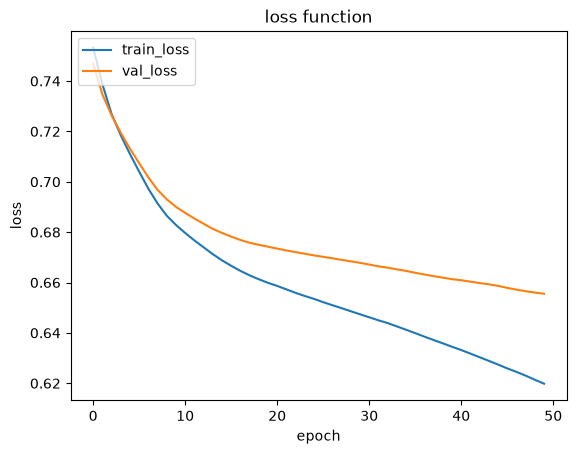

In [24]:
# compare training and validation loss function
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('loss function')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train_loss', 'val_loss'], loc='upper left')
plt.show()

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


/var/folders/21/k1wm74wx1dj0gk3xwfc4vhkh0000gn/T/ipykernel_18934/3977616084.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(labels)
/var/folders/21/k1wm74wx1dj0gk3xwfc4vhkh0000gn/T/ipykernel_18934/3977616084.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(labels)


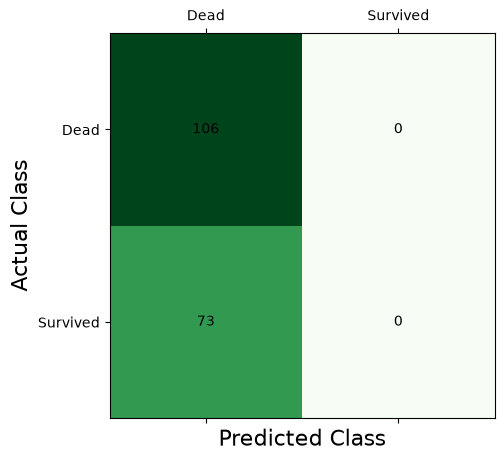

accuracy: 0.5921787709497207
precision: 0.0
recall: 0.0
F1 Score:  0.0


In [26]:

# calculate confusion matrix
Y_pred = model.predict(X_test)
Y_pred_classes = np.rint(Y_pred)
cm = confusion_matrix(y_test, Y_pred_classes)

#create and plot confusion matrix figure content
fig, ax = plt.subplots(figsize=(5, 5))
labels = ['','Dead','Survived']
ax.set_xticklabels(labels)
ax.set_yticklabels(labels)
ax.matshow(cm, cmap=plt.cm.Greens)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(x=j, y=i,s=cm[i, j], va='center', ha='center')

plt.xlabel('Predicted Class', fontsize=16)
plt.ylabel('Actual Class', fontsize=16)
plt.show()

#print precision & recall
accuracy = (cm[0][0] + cm[1][1]) / (cm[0][0]+cm[1][0]+cm[0][1]+cm[1][1])
predicted_positives = cm[0][1] + cm[1][1]
actual_positives = cm[1][0] + cm[1][1]
precision = cm[1][1] / predicted_positives if predicted_positives else 0.0
recall = cm[1][1] / actual_positives if actual_positives else 0.0
f1_denominator = precision + recall
f1 = 2 * precision * recall / f1_denominator if f1_denominator else 0.0

print("accuracy:", accuracy)
print("precision:", precision)
print("recall:", recall)
print("F1 Score: ", f1)

#### **Experiment with number of hidden layers**
- Number of hidden layers: Maybe adding more hidden layers improves the model?

In [59]:
# increasing the number of hidden layers

model = tf.keras.Sequential([
    tf.keras.layers.Dense(2, input_dim=17, activation="relu"),
    tf.keras.layers.Dense(2, activation="relu"),
    tf.keras.layers.Dense(2, activation="relu"),
    tf.keras.layers.Dense(2, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(optimizer="sgd",
              loss='binary_crossentropy',
              metrics=["mse","mae", "binary_crossentropy", "accuracy"])


# train the model
history = model.fit(X_train, y_train, epochs=50, validation_data=(X_test, y_test))

Epoch 1/50


/Users/max/Documents/GitHub/ai-basics/titanic-challenge.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6222 - binary_crossentropy: 0.6916 - loss: 0.6916 - mae: 0.4992 - mse: 0.2492 - val_accuracy: 0.5922 - val_binary_crossentropy: 0.6907 - val_loss: 0.6907 - val_mae: 0.4987 - val_mse: 0.2488
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6222 - binary_crossentropy: 0.6885 - loss: 0.6885 - mae: 0.4976 - mse: 0.2477 - val_accuracy: 0.5922 - val_binary_crossentropy: 0.6886 - val_loss: 0.6886 - val_mae: 0.4975 - val_mse: 0.2477
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6222 - binary_crossentropy: 0.6858 - loss: 0.6858 - mae: 0.4961 - mse: 0.2463 - val_accuracy: 0.5922 - val_binary_crossentropy: 0.6867 - val_loss: 0.6867 - val_mae: 0.4964 - val_mse: 0.2468
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6222 - binary_crossentropy: 0.6833 - loss: 0.6833 - mae: 0.4946 - mse: 0.2451 - val_accuracy: 0.5922 - val_binary_crossentropy: 0.6851 - val_loss: 0.6851 - val_mae: 0.4953 - val_mse: 0.

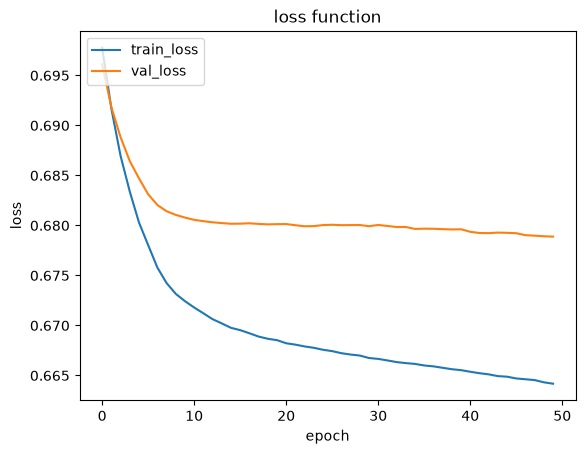

In [28]:
# compare training and validation loss function
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('loss function')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train_loss', 'val_loss'], loc='upper left')
plt.show()

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


/var/folders/21/k1wm74wx1dj0gk3xwfc4vhkh0000gn/T/ipykernel_18934/2900421573.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(labels)
/var/folders/21/k1wm74wx1dj0gk3xwfc4vhkh0000gn/T/ipykernel_18934/2900421573.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(labels)


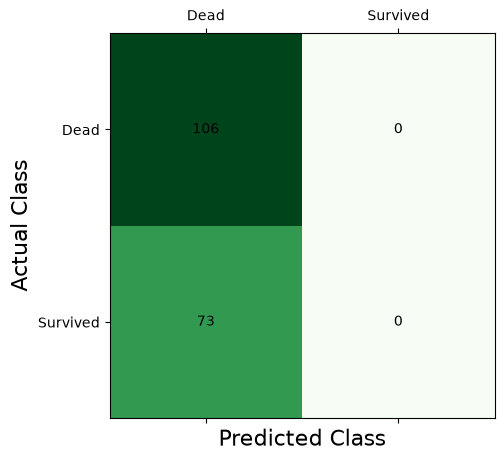

accuracy: 0.5921787709497207
precision: 0.0
recall: 0.0
F1 Score:  0.0


In [30]:
# calculate confusion matrix
Y_pred = model.predict(X_test)
Y_pred_classes = np.rint(Y_pred)
cm = confusion_matrix(y_test, Y_pred_classes)

#create and plot confusion matrix figure content
fig, ax = plt.subplots(figsize=(5, 5))
labels = ['','Dead','Survived']
ax.set_xticklabels(labels)
ax.set_yticklabels(labels)
ax.matshow(cm, cmap=plt.cm.Greens)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(x=j, y=i,s=cm[i, j], va='center', ha='center')

plt.xlabel('Predicted Class', fontsize=16)
plt.ylabel('Actual Class', fontsize=16)
plt.show()

#print precision & recall
accuracy = (cm[0][0] + cm[1][1]) / (cm[0][0]+cm[1][0]+cm[0][1]+cm[1][1])
predicted_positives = cm[0][1] + cm[1][1]
actual_positives = cm[1][0] + cm[1][1]
precision = cm[1][1] / predicted_positives if predicted_positives else 0.0
recall = cm[1][1] / actual_positives if actual_positives else 0.0
f1_denominator = precision + recall
f1 = 2 * precision * recall / f1_denominator if f1_denominator else 0.0

print("accuracy:", accuracy)
print("precision:", precision)
print("recall:", recall)
print("F1 Score: ", f1)

#### -> solely increasing the layers didn't improve the model performance

#### **Experiment with number of neurons**
- Number of neurons per layer: The number of neurons in the first and last layer are defined by the data we work with. But the number of neurons in the hidden layers is not. This is something you can experiment with.

In [82]:
# increasing the number of hidden layers

model = tf.keras.Sequential([
    tf.keras.layers.Dense(446, input_dim=17, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(optimizer="sgd",
              loss='binary_crossentropy',
              metrics=["mse","mae", "binary_crossentropy", "accuracy"])


# train the model
history = model.fit(X_train, y_train, epochs=50, validation_data=(X_test, y_test))

Epoch 1/50
 1/23 ━━━━━━━━━━━━━━━━━━━━ 3s 166ms/step - accuracy: 0.4688 - binary_crossentropy: 0.6882 - loss: 0.6882 - mae: 0.4972 - mse: 0.2475

/Users/max/Documents/GitHub/ai-basics/titanic-challenge.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6208 - binary_crossentropy: 0.6758 - loss: 0.6758 - mae: 0.4902 - mse: 0.2414 - val_accuracy: 0.5698 - val_binary_crossentropy: 0.6796 - val_loss: 0.6796 - val_mae: 0.4913 - val_mse: 0.2433
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6671 - binary_crossentropy: 0.6548 - loss: 0.6548 - mae: 0.4781 - mse: 0.2309 - val_accuracy: 0.5922 - val_binary_crossentropy: 0.6673 - val_loss: 0.6673 - val_mae: 0.4828 - val_mse: 0.2372
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6798 - binary_crossentropy: 0.6377 - loss: 0.6377 - mae: 0.4674 - mse: 0.2226 - val_accuracy: 0.6089 - val_binary_crossentropy: 0.6573 - val_loss: 0.6573 - val_mae: 0.4753 - val_mse: 0.2324
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6980 - binary_crossentropy: 0.6237 - loss: 0.6237 - mae: 0.4582 - mse: 0.2159 - val_accuracy: 0.6257 - val_binary_crossentropy: 0.6484 - val_loss: 0.6484 - val_mae: 0.4682 - val_mse: 0.

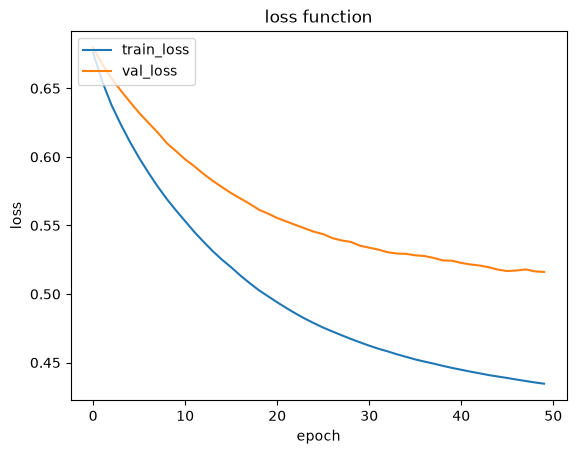

In [83]:
# compare training and validation loss function
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('loss function')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train_loss', 'val_loss'], loc='upper left')
plt.show()

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


/var/folders/21/k1wm74wx1dj0gk3xwfc4vhkh0000gn/T/ipykernel_18934/2900421573.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(labels)
/var/folders/21/k1wm74wx1dj0gk3xwfc4vhkh0000gn/T/ipykernel_18934/2900421573.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(labels)


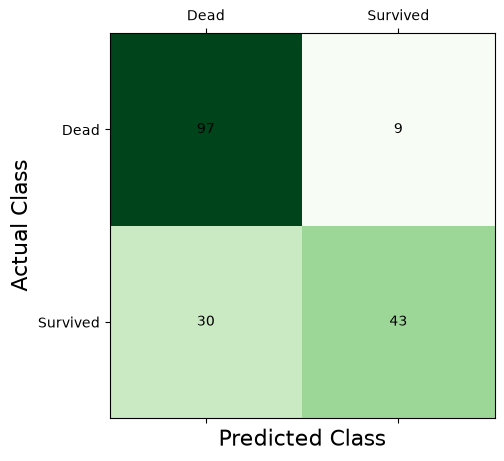

accuracy: 0.7821229050279329
precision: 0.8269230769230769
recall: 0.589041095890411
F1 Score:  0.6880000000000001


In [84]:
# calculate confusion matrix
Y_pred = model.predict(X_test)
Y_pred_classes = np.rint(Y_pred)
cm = confusion_matrix(y_test, Y_pred_classes)

#create and plot confusion matrix figure content
fig, ax = plt.subplots(figsize=(5, 5))
labels = ['','Dead','Survived']
ax.set_xticklabels(labels)
ax.set_yticklabels(labels)
ax.matshow(cm, cmap=plt.cm.Greens)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(x=j, y=i,s=cm[i, j], va='center', ha='center')

plt.xlabel('Predicted Class', fontsize=16)
plt.ylabel('Actual Class', fontsize=16)
plt.show()

#print precision & recall
accuracy = (cm[0][0] + cm[1][1]) / (cm[0][0]+cm[1][0]+cm[0][1]+cm[1][1])
predicted_positives = cm[0][1] + cm[1][1]
actual_positives = cm[1][0] + cm[1][1]
precision = cm[1][1] / predicted_positives if predicted_positives else 0.0
recall = cm[1][1] / actual_positives if actual_positives else 0.0
f1_denominator = precision + recall
f1 = 2 * precision * recall / f1_denominator if f1_denominator else 0.0

print("accuracy:", accuracy)
print("precision:", precision)
print("recall:", recall)
print("F1 Score: ", f1)

#### -> increasing the amount of neurons improved the accuracy

#### **Experiment with activation functions**

In [ ]:
# trying the functions MULTIPLE times:
# https://www.geeksforgeeks.org/machine-learning/activation-functions-neural-networks/
# relu (accuracy=0.6222 - 0.8216)
# sigmoid (accuracy=0.6222)
# tanh (accuracy=0.6503 - 0.8287)
# softplus (accuracy=0.6222 - 0.7851)
# elu (accuracy=0.7486 - 0.8329)
# selu (accuracy=0.7978 - 0.8315)

model = tf.keras.Sequential([
    tf.keras.layers.Dense(2, input_dim=17, activation="selu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(optimizer="sgd",
              loss='binary_crossentropy',
              metrics=["mse","mae", "binary_crossentropy", "accuracy"])


# train the model
history = model.fit(X_train, y_train, epochs=50, validation_data=(X_test, y_test))

Epoch 1/50
 1/23 ━━━━━━━━━━━━━━━━━━━━ 3s 171ms/step - accuracy: 0.5625 - binary_crossentropy: 0.7145 - loss: 0.7145 - mae: 0.4895 - mse: 0.2600

/Users/max/Documents/GitHub/ai-basics/titanic-challenge.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6180 - binary_crossentropy: 0.6600 - loss: 0.6600 - mae: 0.4631 - mse: 0.2339 - val_accuracy: 0.5922 - val_binary_crossentropy: 0.6667 - val_loss: 0.6667 - val_mae: 0.4675 - val_mse: 0.2369
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6601 - binary_crossentropy: 0.6390 - loss: 0.6390 - mae: 0.4526 - mse: 0.2238 - val_accuracy: 0.6089 - val_binary_crossentropy: 0.6528 - val_loss: 0.6528 - val_mae: 0.4597 - val_mse: 0.2303
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6826 - binary_crossentropy: 0.6224 - loss: 0.6224 - mae: 0.4429 - mse: 0.2159 - val_accuracy: 0.6369 - val_binary_crossentropy: 0.6434 - val_loss: 0.6434 - val_mae: 0.4535 - val_mse: 0.2257
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6910 - binary_crossentropy: 0.6103 - loss: 0.6103 - mae: 0.4354 - mse: 0.2102 - val_accuracy: 0.6313 - val_binary_crossentropy: 0.6360 - val_loss: 0.6360 - val_mae: 0.4480 - val_mse: 0.

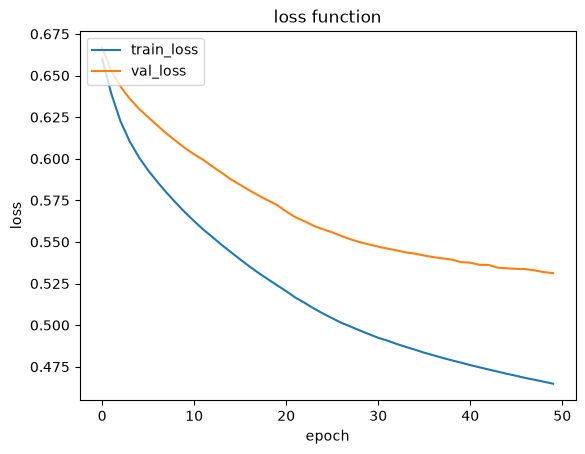

In [160]:
# compare training and validation loss function
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('loss function')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train_loss', 'val_loss'], loc='upper left')
plt.show()

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


/var/folders/21/k1wm74wx1dj0gk3xwfc4vhkh0000gn/T/ipykernel_18934/2900421573.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(labels)
/var/folders/21/k1wm74wx1dj0gk3xwfc4vhkh0000gn/T/ipykernel_18934/2900421573.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(labels)


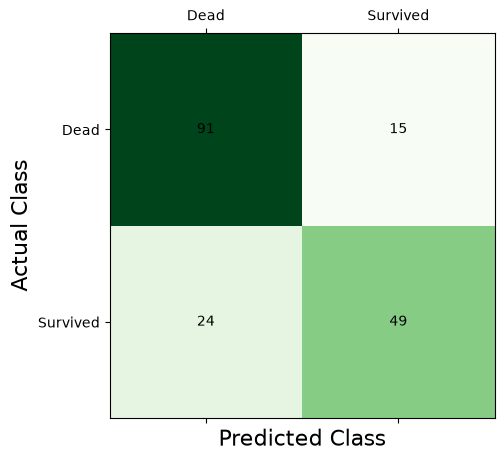

accuracy: 0.7821229050279329
precision: 0.765625
recall: 0.6712328767123288
F1 Score:  0.7153284671532847


In [161]:
# calculate confusion matrix
Y_pred = model.predict(X_test)
Y_pred_classes = np.rint(Y_pred)
cm = confusion_matrix(y_test, Y_pred_classes)

#create and plot confusion matrix figure content
fig, ax = plt.subplots(figsize=(5, 5))
labels = ['','Dead','Survived']
ax.set_xticklabels(labels)
ax.set_yticklabels(labels)
ax.matshow(cm, cmap=plt.cm.Greens)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(x=j, y=i,s=cm[i, j], va='center', ha='center')

plt.xlabel('Predicted Class', fontsize=16)
plt.ylabel('Actual Class', fontsize=16)
plt.show()

#print precision & recall
accuracy = (cm[0][0] + cm[1][1]) / (cm[0][0]+cm[1][0]+cm[0][1]+cm[1][1])
predicted_positives = cm[0][1] + cm[1][1]
actual_positives = cm[1][0] + cm[1][1]
precision = cm[1][1] / predicted_positives if predicted_positives else 0.0
recall = cm[1][1] / actual_positives if actual_positives else 0.0
f1_denominator = precision + recall
f1 = 2 * precision * recall / f1_denominator if f1_denominator else 0.0

print("accuracy:", accuracy)
print("precision:", precision)
print("recall:", recall)
print("F1 Score: ", f1)

#### -> selu (Scaled Exponential Linear Unit)
SELU is a scaled version of ELU designed for self-normalizing neural networks, helping maintain stable activations during training.

#### **Experiment with optimizer**
The network below uses sgd as optimizer. Maybe another one could work better for this problem?

In [212]:
# experiment with the optimizer for model.compile MULTIPLE times:
# https://ml-cheatsheet.readthedocs.io/en/latest/optimizers.html
# sgd (accuracy = 0.7626 - 0.8329)
# adagrad (accurarcy = 0.3567 - 0.6433)
# adadelta (accurarcy = 0.4256 - 0.7008)
# adam (accuracy = 0.8315 - 0.8343)
# rmsprop (accuracy = 0.8315 - 0.8413)

model = tf.keras.Sequential([
    tf.keras.layers.Dense(2, input_dim=17, activation="selu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(optimizer="rmsprop",
              loss='binary_crossentropy',
              metrics=["mse","mae", "binary_crossentropy", "accuracy"])


# train the model
history = model.fit(X_train, y_train, epochs=50, validation_data=(X_test, y_test))

Epoch 1/50


/Users/max/Documents/GitHub/ai-basics/titanic-challenge.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6320 - binary_crossentropy: 0.6600 - loss: 0.6600 - mae: 0.4380 - mse: 0.2329 - val_accuracy: 0.6592 - val_binary_crossentropy: 0.6287 - val_loss: 0.6287 - val_mae: 0.4300 - val_mse: 0.2199
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6433 - binary_crossentropy: 0.6377 - loss: 0.6377 - mae: 0.4309 - mse: 0.2232 - val_accuracy: 0.6760 - val_binary_crossentropy: 0.6143 - val_loss: 0.6143 - val_mae: 0.4249 - val_mse: 0.2132
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6517 - binary_crossentropy: 0.6193 - loss: 0.6193 - mae: 0.4251 - mse: 0.2149 - val_accuracy: 0.6816 - val_binary_crossentropy: 0.6015 - val_loss: 0.6015 - val_mae: 0.4186 - val_mse: 0.2073
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6728 - binary_crossentropy: 0.6017 - loss: 0.6017 - mae: 0.4177 - mse: 0.2068 - val_accuracy: 0.6983 - val_binary_crossentropy: 0.5888 - val_loss: 0.5888 - val_mae: 0.4122 - val_mse: 0.

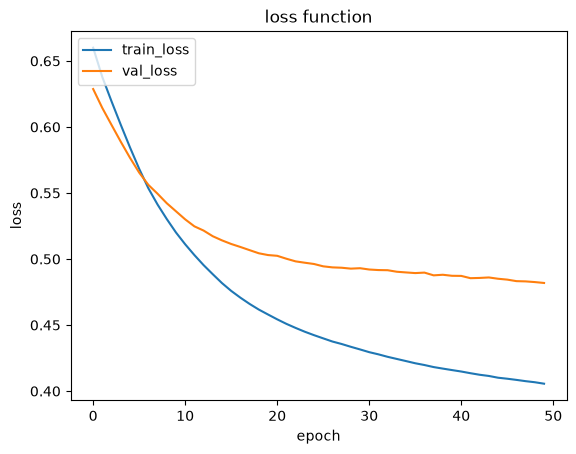

In [213]:
# compare training and validation loss function
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('loss function')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train_loss', 'val_loss'], loc='upper left')
plt.show()

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


/var/folders/21/k1wm74wx1dj0gk3xwfc4vhkh0000gn/T/ipykernel_18934/2900421573.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(labels)
/var/folders/21/k1wm74wx1dj0gk3xwfc4vhkh0000gn/T/ipykernel_18934/2900421573.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(labels)


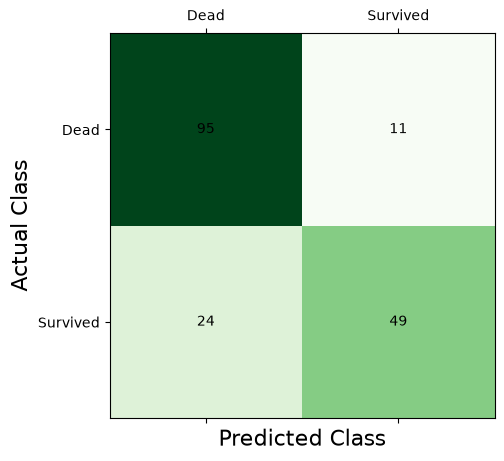

accuracy: 0.8044692737430168
precision: 0.8166666666666667
recall: 0.6712328767123288
F1 Score:  0.7368421052631579


In [214]:
# calculate confusion matrix
Y_pred = model.predict(X_test)
Y_pred_classes = np.rint(Y_pred)
cm = confusion_matrix(y_test, Y_pred_classes)

#create and plot confusion matrix figure content
fig, ax = plt.subplots(figsize=(5, 5))
labels = ['','Dead','Survived']
ax.set_xticklabels(labels)
ax.set_yticklabels(labels)
ax.matshow(cm, cmap=plt.cm.Greens)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(x=j, y=i,s=cm[i, j], va='center', ha='center')

plt.xlabel('Predicted Class', fontsize=16)
plt.ylabel('Actual Class', fontsize=16)
plt.show()

#print precision & recall
accuracy = (cm[0][0] + cm[1][1]) / (cm[0][0]+cm[1][0]+cm[0][1]+cm[1][1])
predicted_positives = cm[0][1] + cm[1][1]
actual_positives = cm[1][0] + cm[1][1]
precision = cm[1][1] / predicted_positives if predicted_positives else 0.0
recall = cm[1][1] / actual_positives if actual_positives else 0.0
f1_denominator = precision + recall
f1 = 2 * precision * recall / f1_denominator if f1_denominator else 0.0

print("accuracy:", accuracy)
print("precision:", precision)
print("recall:", recall)
print("F1 Score: ", f1)

#### -> Adam and RMSProp show the best accuracy
- adam (accuracy = 0.8315 - 0.8343)
- rmsprop (accuracy = 0.8315 - 0.8413)

#### **Experiment with epochs and bringing the learnings together**
The network trains for 50 epochs. Do you think this is the right number? Is it maybe too short? Or too long?

In [263]:
"""

use the following learnings to reach best improvement:
-> more neurons, maybe in combination with additional layers
-> selu as activation function
-> Adam or RMSprop as optimizer

"""

model = tf.keras.Sequential([
    tf.keras.layers.Dense(8, input_dim=17, activation="selu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(optimizer="rmsprop",
              loss='binary_crossentropy',
              metrics=["mse","mae", "binary_crossentropy", "accuracy"])


# train the model
history = model.fit(X_train, y_train, epochs=20, validation_data=(X_test, y_test))

Epoch 1/20


/Users/max/Documents/GitHub/ai-basics/titanic-challenge.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5112 - binary_crossentropy: 0.7266 - loss: 0.7266 - mae: 0.4989 - mse: 0.2653 - val_accuracy: 0.4749 - val_binary_crossentropy: 0.7251 - val_loss: 0.7251 - val_mae: 0.4993 - val_mse: 0.2648
Epoch 2/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5815 - binary_crossentropy: 0.6822 - loss: 0.6822 - mae: 0.4760 - mse: 0.2443 - val_accuracy: 0.5698 - val_binary_crossentropy: 0.6958 - val_loss: 0.6958 - val_mae: 0.4815 - val_mse: 0.2509
Epoch 3/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6264 - binary_crossentropy: 0.6499 - loss: 0.6499 - mae: 0.4559 - mse: 0.2292 - val_accuracy: 0.5754 - val_binary_crossentropy: 0.6713 - val_loss: 0.6713 - val_mae: 0.4671 - val_mse: 0.2395
Epoch 4/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6503 - binary_crossentropy: 0.6238 - loss: 0.6238 - mae: 0.4418 - mse: 0.2172 - val_accuracy: 0.5866 - val_binary_crossentropy: 0.6503 - val_loss: 0.6503 - val_mae: 0.4543 - val_mse: 0.

##### Tests

###### Finding a number of neurons and if added hidden layers have still no effect
**32 neurons**, 0 added hidden layers, selu as activation function and Adam as optimizer, epochs = 50
-> accuracy = 0.8469 - 0.8553

**8 neurons**, 0 added hidden layers, selu as activation function and Adam as optimizer, epochs = 50
-> accuracy = 0.8343 - 0.8413

32 neurons, **3 added hidden layers**, selu as activation function and Adam as optimizer, epochs = 50
-> accuracy = 0.8511 - 0.8624

###### Testing the number of epochs based on loss function
8 neurons, 0 added hidden layers, selu as activation function and Adam as optimizer, **epochs = 50**
-> train_loss not flatten yet
-> val_loss flatten at around 20-30 epochs

8 neurons, 0 added hidden layers, selu as activation function and Adam as optimizer, **epochs = 20**
-> train_loss not flatten yet
-> val_loss flattened

8 neurons, 0 added hidden layers, selu as activation function and Adam as optimizer, **epochs = 100**
-> train_loss flattens at around 70-90
-> val_loss flattened and noisy

8 neurons, 0 added hidden layers, selu as activation function and Adam as optimizer, **epochs = 80**
-> train_loss flattened
-> val_loss flattened and noisy

###### Comparing Adam and RMSProp with final set of neurons, layers and epochs
8 neuros, 0 added hidden layers, selu as activation function and **RMSProp as optimizer**, epochs = 20
-> accuracy = 0.8062 - 0.8385

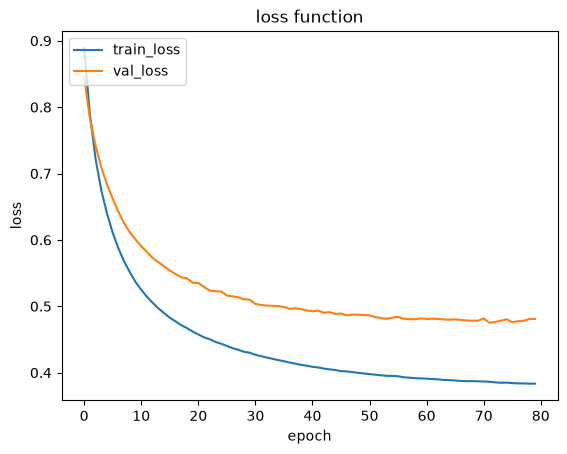

In [256]:
# compare training and validation loss function
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('loss function')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train_loss', 'val_loss'], loc='upper left')
plt.show()

In [ ]:
# calculate confusion matrix
Y_pred = model.predict(X_test)
Y_pred_classes = np.rint(Y_pred)
cm = confusion_matrix(y_test, Y_pred_classes)

#create and plot confusion matrix figure content
fig, ax = plt.subplots(figsize=(5, 5))
labels = ['','Dead','Survived']
ax.set_xticklabels(labels)
ax.set_yticklabels(labels)
ax.matshow(cm, cmap=plt.cm.Greens)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(x=j, y=i,s=cm[i, j], va='center', ha='center')

plt.xlabel('Predicted Class', fontsize=16)
plt.ylabel('Actual Class', fontsize=16)
plt.show()

#print precision & recall
accuracy = (cm[0][0] + cm[1][1]) / (cm[0][0]+cm[1][0]+cm[0][1]+cm[1][1])
predicted_positives = cm[0][1] + cm[1][1]
actual_positives = cm[1][0] + cm[1][1]
precision = cm[1][1] / predicted_positives if predicted_positives else 0.0
recall = cm[1][1] / actual_positives if actual_positives else 0.0
f1_denominator = precision + recall
f1 = 2 * precision * recall / f1_denominator if f1_denominator else 0.0

print("accuracy:", accuracy)
print("precision:", precision)
print("recall:", recall)
print("F1 Score: ", f1)

#### -> Final set of hyperparameters: 
neurons = 32, 
hidden layers = 0, 
activation = selu,
optimizer = adam, 
epochs = 20

#### **Running the optimized model**

In [291]:
model = tf.keras.Sequential([
    tf.keras.layers.Dense(32, input_dim=17, activation="selu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(optimizer="adam",
              loss='binary_crossentropy',
              metrics=["mse","mae", "binary_crossentropy", "accuracy"])


# train the model
history = model.fit(X_train, y_train, epochs=20, validation_data=(X_test, y_test))

Epoch 1/20


/Users/max/Documents/GitHub/ai-basics/titanic-challenge.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6278 - binary_crossentropy: 0.6672 - loss: 0.6672 - mae: 0.4558 - mse: 0.2349 - val_accuracy: 0.6145 - val_binary_crossentropy: 0.6452 - val_loss: 0.6452 - val_mae: 0.4440 - val_mse: 0.2260
Epoch 2/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7261 - binary_crossentropy: 0.5793 - loss: 0.5793 - mae: 0.4098 - mse: 0.1954 - val_accuracy: 0.6983 - val_binary_crossentropy: 0.5883 - val_loss: 0.5883 - val_mae: 0.4086 - val_mse: 0.2005
Epoch 3/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7907 - binary_crossentropy: 0.5251 - loss: 0.5251 - mae: 0.3730 - mse: 0.1713 - val_accuracy: 0.7430 - val_binary_crossentropy: 0.5619 - val_loss: 0.5619 - val_mae: 0.3841 - val_mse: 0.1885
Epoch 4/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8006 - binary_crossentropy: 0.4926 - loss: 0.4926 - mae: 0.3500 - mse: 0.1576 - val_accuracy: 0.7486 - val_binary_crossentropy: 0.5404 - val_loss: 0.5404 - val_mae: 0.3659 - val_mse: 0.

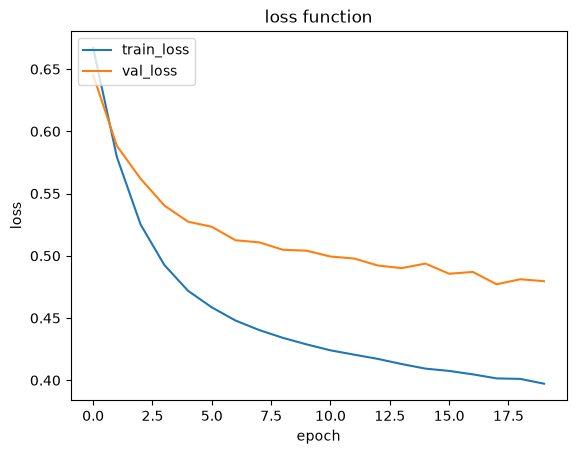

In [292]:
# compare training and validation loss function
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('loss function')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train_loss', 'val_loss'], loc='upper left')
plt.show()

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


/var/folders/21/k1wm74wx1dj0gk3xwfc4vhkh0000gn/T/ipykernel_18934/2900421573.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(labels)
/var/folders/21/k1wm74wx1dj0gk3xwfc4vhkh0000gn/T/ipykernel_18934/2900421573.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(labels)


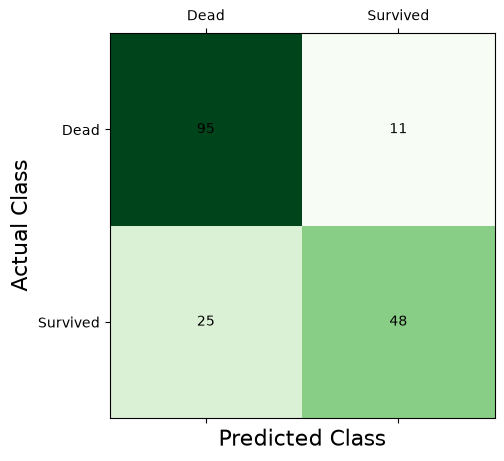

accuracy: 0.7988826815642458
precision: 0.8135593220338984
recall: 0.6575342465753424
F1 Score:  0.7272727272727273


In [293]:
# calculate confusion matrix
Y_pred = model.predict(X_test)
Y_pred_classes = np.rint(Y_pred)
cm = confusion_matrix(y_test, Y_pred_classes)

#create and plot confusion matrix figure content
fig, ax = plt.subplots(figsize=(5, 5))
labels = ['','Dead','Survived']
ax.set_xticklabels(labels)
ax.set_yticklabels(labels)
ax.matshow(cm, cmap=plt.cm.Greens)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(x=j, y=i,s=cm[i, j], va='center', ha='center')

plt.xlabel('Predicted Class', fontsize=16)
plt.ylabel('Actual Class', fontsize=16)
plt.show()

#print precision & recall
accuracy = (cm[0][0] + cm[1][1]) / (cm[0][0]+cm[1][0]+cm[0][1]+cm[1][1])
predicted_positives = cm[0][1] + cm[1][1]
actual_positives = cm[1][0] + cm[1][1]
precision = cm[1][1] / predicted_positives if predicted_positives else 0.0
recall = cm[1][1] / actual_positives if actual_positives else 0.0
f1_denominator = precision + recall
f1 = 2 * precision * recall / f1_denominator if f1_denominator else 0.0

print("accuracy:", accuracy)
print("precision:", precision)
print("recall:", recall)
print("F1 Score: ", f1)

#### Final evaluations

##### _What your evaluation of the best model is. Is the result good or bad? Why? In addition to the actual score, please also discuss overfitting._
- If the result is good or bad, can be mostly seen with the confusion matrix. The original model wasn't able to predict any survivor, it basically declared everyone dead and with that reasoning had a 100% accuracy to predict a dead person as actually dead. 
- The improved model can now actually predict survivors, yet the accuracy for predicted deaths drops.
- The improved model still is lacking to predict survivors but is at least not predicting everyone as dead to achieve the "baseline" accuracy of 59.2%.
- I ran into overfitting when I tried increasing the neurons. I went all the way up to 1000+ neurons to just see if anything changes and found with a bit of testing a point where not much more happened, which is 446 neurons. With 17 inputs and 446 neurons that would add up to 8475 parameters compared with 712 training rows. At that point the model is probably not "learning" anymore but "memorising".

##### _Any other observations you made during the experiment._
- It makes sense that the more parameters you train, meaning for example more neurons, the model should become somehow more accurate. So for me it was more interesting to see how the activation functions and optimizers changed the model behaviour. 
- I would assume if you fully understand the functions and optimizers it will be easy to quickly find a suitable pairing without testing every combination and direction.
- What is a reasonable amount to run each model configuration? It became quite clear that the results can vary quite a bit per run. My method was to find the range and once I had three runs that were in that range I stopped testing.